# DineScope — Task 1: Restaurant Rating Prediction
## Verification, Evaluation & Demonstration

This notebook verifies the outputs created by the Python implementation in `src/`. It does not duplicate data cleaning, model training or hyperparameter tuning. It loads the saved datasets, models, reports and figures, then checks inference and presents the results.

## 1. Setup and project paths
Run from the project root or the `notebooks/` folder.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

# Locate the DineScope project root

def find_project_root() -> Path:
    cwd = Path.cwd()

    for p in [cwd, *cwd.parents]:
        if (p / "src").is_dir() and (p / "data").is_dir():
            return p

    raise FileNotFoundError(
        "Could not locate the DineScope project root."
    )


PROJECT_ROOT = find_project_root()

# Define project directories
DATA = PROJECT_ROOT / "data" / "processed" / "task_1_rating_prediction"
MODELS = PROJECT_ROOT / "models" / "task_1"
REPORTS = PROJECT_ROOT / "reports" / "task_1"
FIGURES = PROJECT_ROOT / "outputs" / "figures" / "task_1"

print("=" * 75)
print("DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS")
print("TASK 01: RESTAURANT RATING PREDICTION")
print("NOTEBOOK: RATING PREDICTION VERIFICATION")
print("=" * 75)

print("Project root:", PROJECT_ROOT)
print("Processed data:", DATA)
print("Models:", MODELS)
print("Reports:", REPORTS)
print("Figures:", FIGURES)

print("\nProject directories validated successfully.")

DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS
TASK 01: RESTAURANT RATING PREDICTION
NOTEBOOK: RATING PREDICTION VERIFICATION
Project root: c:\Users\kamal\OneDrive\Desktop\DineScope
Processed data: c:\Users\kamal\OneDrive\Desktop\DineScope\data\processed\task_1_rating_prediction
Models: c:\Users\kamal\OneDrive\Desktop\DineScope\models\task_1
Reports: c:\Users\kamal\OneDrive\Desktop\DineScope\reports\task_1
Figures: c:\Users\kamal\OneDrive\Desktop\DineScope\outputs\figures\task_1

Project directories validated successfully.


## 2. Check expected artifacts
Missing files are reported so you can run the corresponding `src/` script.

In [2]:
expected = [
    DATA / "train.csv", DATA / "test.csv", REPORTS / "feature_config.json",
    MODELS / "tuned_rating_model_without_votes.joblib",
    MODELS / "tuned_rating_model_with_votes.joblib",
    REPORTS / "rating_tuning_comparison.csv",
    REPORTS / "final_rating_model_evaluation.csv",
    REPORTS / "final_feature_importance_comparison.csv",
    REPORTS / "final_cross_validation_comparison.csv",
    REPORTS / "final_model_selection_summary.txt",
    REPORTS / "rating_pipeline_test_predictions.csv",
    REPORTS / "rating_pipeline_validation_summary.csv",
]
status = pd.DataFrame({"Artifact":[str(p.relative_to(PROJECT_ROOT)) for p in expected],
                       "Exists":[p.exists() for p in expected]})
display(status)

,Artifact,Exists
0,data\processed\task_1_rating_prediction\train.csv,True
1,data\processed\task_1_rating_prediction\test.csv,True
2,reports\task_1\feature_config.json,True
3,models\task_1\tuned_rating_model_without_votes...,True
4,models\task_1\tuned_rating_model_with_votes.jo...,True
5,reports\task_1\rating_tuning_comparison.csv,True
6,reports\task_1\final_rating_model_evaluation.csv,True
7,reports\task_1\final_feature_importance_compar...,True
8,reports\task_1\final_cross_validation_comparis...,True
9,reports\task_1\final_model_selection_summary.txt,True


## 3. Verify processed training and test data
The original dataset contained 9,551 records. The rating task retained 7,403 rated restaurants after excluding 2,148 unrated records. The preprocessing script created the train/test split; this notebook only checks those saved files.

In [3]:
train_path, test_path = DATA / "train.csv", DATA / "test.csv"
train_df = pd.read_csv(train_path) if train_path.exists() else None
test_df = pd.read_csv(test_path) if test_path.exists() else None

if train_df is not None and test_df is not None:
    print("Train shape:", train_df.shape, "| Test shape:", test_df.shape)
    target = "Aggregate rating"
    assert target in train_df.columns and target in test_df.columns
    display(pd.DataFrame({
        "Split":["Train","Test"],
        "Rows":[len(train_df),len(test_df)],
        "Target mean":[train_df[target].mean(),test_df[target].mean()],
        "Target min":[train_df[target].min(),test_df[target].min()],
        "Target max":[train_df[target].max(),test_df[target].max()],
        "Missing values":[train_df.isna().sum().sum(),test_df.isna().sum().sum()]
    }))
else:
    print("Train/test CSV files are missing.")

Train shape: (5922, 10) | Test shape: (1481, 10)


,Split,Rows,Target mean,Target min,Target max,Missing values
0,Train,5922,3.440831,1.8,4.9,0
1,Test,1481,3.436799,2.1,4.9,0


### 3.1 Feature configuration

In [4]:
config_path = REPORTS / "feature_config.json"
if config_path.exists():
    feature_config = json.loads(config_path.read_text(encoding="utf-8"))
    print(json.dumps(feature_config, indent=4))
else:
    print("feature_config.json not found.")

{
    "target": "Aggregate rating",
    "base_features": [
        "Country Code",
        "City",
        "Longitude",
        "Latitude",
        "Cuisines",
        "Has Table booking",
        "Has Online delivery",
        "Price range"
    ],
    "features_with_votes": [
        "Country Code",
        "City",
        "Longitude",
        "Latitude",
        "Cuisines",
        "Has Table booking",
        "Has Online delivery",
        "Price range",
        "Votes"
    ],
    "random_state": 42,
    "test_size": 0.2,
    "excluded_features": [
        "Restaurant ID",
        "Restaurant Name",
        "Address",
        "Locality",
        "Locality Verbose",
        "Average Cost for two",
        "Currency",
        "Rating color",
        "Rating text",
        "Is delivering now",
        "Switch to order menu"
    ]
}


## 4. Load final trained models
These are saved tuned pipelines. Loading them does not retrain the models.

In [5]:
model_paths = {
    "Without Votes": MODELS / "tuned_rating_model_without_votes.joblib",
    "With Votes": MODELS / "tuned_rating_model_with_votes.joblib",
}
models = {}
for name, path in model_paths.items():
    if path.exists():
        models[name] = joblib.load(path)
        print("Loaded:", name, "->", path.name)
    else:
        print("Missing:", path)

Loaded: Without Votes -> tuned_rating_model_without_votes.joblib
Loaded: With Votes -> tuned_rating_model_with_votes.joblib


## 5. Review initial algorithm comparison
The original experiment compared Dummy Regressor, Linear Regression, Ridge Regression, Decision Tree, Random Forest and Extra Trees. Dummy Regressor is a simple baseline, not a feature-learning model.

In [6]:
path = REPORTS / "rating_tuning_comparison.csv"
if path.exists():
    tuning_comparison = pd.read_csv(path)
    display(tuning_comparison)
else:
    print("rating_tuning_comparison.csv not found.")

,Configuration,Best CV RMSE,Baseline Test RMSE,Tuned Test RMSE,Baseline Test MAE,Tuned Test MAE,Baseline Test R2,Tuned Test R2,RMSE Improvement,Best Parameters
0,without_votes,0.39659,0.392266,0.385998,0.303618,0.299258,0.502483,0.518255,0.006268,"{'regressor__n_estimators': 300, 'regressor__m..."
1,with_votes,0.35646,0.334781,0.333013,0.247135,0.246100,0.637615,0.641432,0.001768,"{'regressor__n_estimators': 300, 'regressor__m..."


## 6. Final model evaluation
MAE and RMSE are expressed in rating points. MSE is squared rating points. R² is not classification accuracy.

In [7]:
path = REPORTS / "final_rating_model_evaluation.csv"
if path.exists():
    final_evaluation = pd.read_csv(path)
    display(final_evaluation)
else:
    print("final_rating_model_evaluation.csv not found.")

,Configuration,Best CV RMSE,Baseline Test RMSE,Tuned Test RMSE,Baseline Test MAE,Tuned Test MAE,Baseline Test R2,Tuned Test R2,RMSE Improvement,Best Parameters,...,R2 Gap,Mean Residual,Maximum Absolute Error,Final Train RMSE,Final Train R2,Final Test MAE,Final Test MSE,Final Test RMSE,Final Test R2,RMSE Improvement Percentage
0,without_votes,0.39659,0.392266,0.385998,0.303618,0.299258,0.502483,0.518255,0.006268,"{'regressor__n_estimators': 300, 'regressor__m...",...,0.165298,-0.000466,1.528615,0.310046,0.683553,0.299258,0.148994,0.385998,0.518255,1.597803
1,with_votes,0.35646,0.334781,0.333013,0.247135,0.246100,0.637615,0.641432,0.001768,"{'regressor__n_estimators': 300, 'regressor__m...",...,0.118923,0.001290,1.283145,0.269811,0.760355,0.246100,0.110898,0.333013,0.641432,0.528045


### 6.1 Reported tuned-model results
These values summarize the completed experiment; the saved CSV report is the full result source.

In [8]:
# Load the latest evaluation results generated by Program 08.

evaluation_path = REPORTS / "final_rating_model_evaluation.csv"

if not evaluation_path.exists():
    raise FileNotFoundError(
        f"Evaluation report not found: {evaluation_path}"
    )

reported = pd.read_csv(evaluation_path)

# Format numerical columns dynamically.
numeric_columns = reported.select_dtypes(
    include="number"
).columns

display(
    reported.style.format({
        column: "{:.4f}"
        for column in numeric_columns
    })
)

,Configuration,Best CV RMSE,Baseline Test RMSE,Tuned Test RMSE,Baseline Test MAE,Tuned Test MAE,Baseline Test R2,Tuned Test R2,RMSE Improvement,Best Parameters,Train MAE,Train RMSE,Train R2,Test MAE,Test MSE,Test RMSE,Test R2,RMSE Gap,R2 Gap,Mean Residual,Maximum Absolute Error,Final Train RMSE,Final Train R2,Final Test MAE,Final Test MSE,Final Test RMSE,Final Test R2,RMSE Improvement Percentage
0,without_votes,0.3966,0.3923,0.3860,0.3036,0.2993,0.5025,0.5183,0.0063,"{'regressor__n_estimators': 300, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 0.7, 'regressor__max_depth': 15}",0.2378,0.3100,0.6836,0.2993,0.1490,0.3860,0.5183,0.0760,0.1653,-0.0005,1.5286,0.3100,0.6836,0.2993,0.1490,0.3860,0.5183,1.5978
1,with_votes,0.3565,0.3348,0.3330,0.2471,0.2461,0.6376,0.6414,0.0018,"{'regressor__n_estimators': 300, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 0.7, 'regressor__max_depth': 15}",0.1964,0.2698,0.7604,0.2461,0.1109,0.3330,0.6414,0.0632,0.1189,0.0013,1.2831,0.2698,0.7604,0.2461,0.1109,0.3330,0.6414,0.5280


### 6.2 Interpretation

The tuned model with Votes achieved a test MAE of about **0.246 rating points**, RMSE of about **0.333**, and R² of about **0.641**. The model without Votes achieved MAE of about **0.299**, RMSE of about **0.386**, and R² of about **0.518**.

Votes improved prediction in this experiment, but may not be available for newly opened restaurants. The model without Votes is therefore a useful fallback. R² is not an accuracy percentage; 0.641 means the model explains approximately 64.1% of the variance in this held-out test set.

## 7. Verify final model selection

In [9]:
path = REPORTS / "final_model_selection_summary.txt"
print(path.read_text(encoding="utf-8") if path.exists()
      else "Final model selection summary not found.")

DINESCOPE - FINAL MODEL SELECTION

Primary model: tuned_rating_model_with_votes.joblib
Fallback model: tuned_rating_model_without_votes.joblib

Selected configuration: with_votes
Best CV RMSE: 0.3565
Test RMSE: 0.3330
Test MAE: 0.2461
Test R2: 0.6414

Selection basis:
Cross-validation RMSE was used for model selection.
The held-out test set was used for final evaluation.
The model with Votes requires vote information at prediction time.



## 8. Run inference with the saved models
Predictions are generated on the existing held-out test set. No model is trained in this notebook.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

prediction_results = {}
metric_rows = []
if test_df is not None:
    y_test = test_df["Aggregate rating"].astype(float)
    for name, model in models.items():
        if not hasattr(model, "feature_names_in_"):
            print(name, ": feature_names_in_ unavailable; skipped.")
            continue
        cols = list(model.feature_names_in_)
        missing = [c for c in cols if c not in test_df.columns]
        if missing:
            print(name, "missing columns:", missing)
            continue
        pred = np.asarray(model.predict(test_df.loc[:, cols]), dtype=float)
        prediction_results[name] = pred
        metric_rows.append({
            "Model":name,
            "MAE":mean_absolute_error(y_test,pred),
            "MSE":mean_squared_error(y_test,pred),
            "RMSE":np.sqrt(mean_squared_error(y_test,pred)),
            "R2":r2_score(y_test,pred),
            "All finite":bool(np.isfinite(pred).all()),
            "Min prediction":pred.min(),
            "Max prediction":pred.max()
        })
    if metric_rows:
        display(pd.DataFrame(metric_rows).round(4))
else:
    print("Test data unavailable.")

,Model,MAE,MSE,RMSE,R2,All finite,Min prediction,Max prediction
0,Without Votes,0.2993,0.1490,0.386,0.5183,True,2.6910,4.5547
1,With Votes,0.2461,0.1109,0.333,0.6414,True,2.7261,4.6629


### 8.1 Prediction validity checks

In [11]:
if prediction_results:
    checks = []
    for name, pred in prediction_results.items():
        checks.append({
            "Model":name,
            "All predictions finite":np.isfinite(pred).all(),
            "All predictions in 1–5":((pred >= 1) & (pred <= 5)).all(),
            "Prediction count":len(pred),
            "Minimum":pred.min(),
            "Maximum":pred.max()
        })
    display(pd.DataFrame(checks))
else:
    print("No predictions available.")

,Model,All predictions finite,All predictions in 1–5,Prediction count,Minimum,Maximum
0,Without Votes,True,True,1481,2.690977,4.554690
1,With Votes,True,True,1481,2.726059,4.662891


## 9. Actual versus predicted ratings

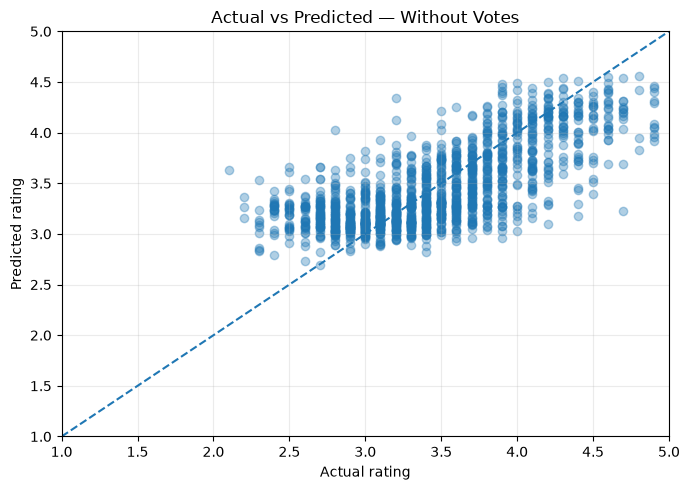

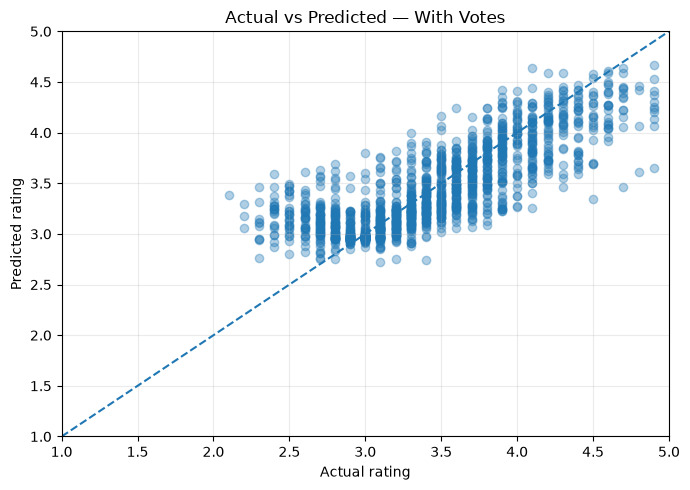

In [12]:
if prediction_results and test_df is not None:
    actual = test_df["Aggregate rating"].astype(float).to_numpy()
    for name, pred in prediction_results.items():
        plt.figure(figsize=(7,5))
        plt.scatter(actual, pred, alpha=0.35)
        plt.plot([1,5],[1,5],"--")
        plt.xlim(1,5); plt.ylim(1,5)
        plt.xlabel("Actual rating"); plt.ylabel("Predicted rating")
        plt.title(f"Actual vs Predicted — {name}")
        plt.grid(alpha=0.25); plt.tight_layout(); plt.show()
else:
    print("Prediction results unavailable; plots skipped.")

## 10. Residual analysis
Residual = actual rating − predicted rating.

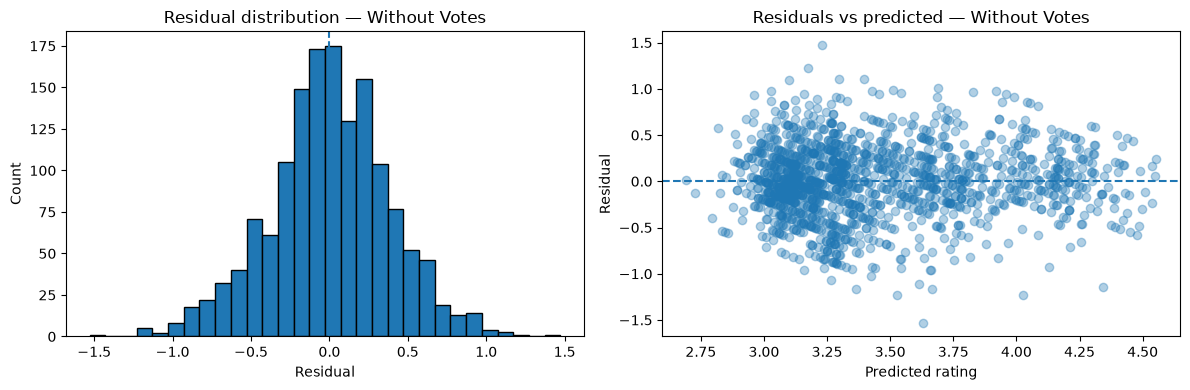

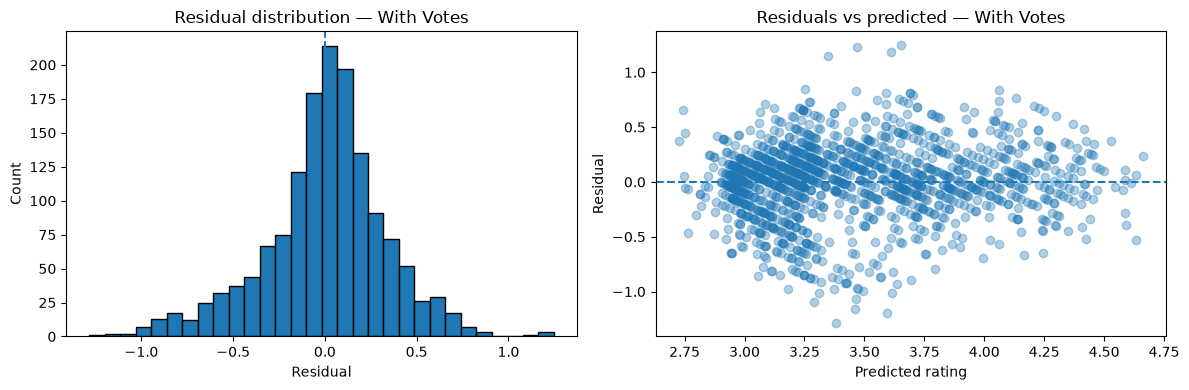

In [13]:
if prediction_results and test_df is not None:
    actual = test_df["Aggregate rating"].astype(float).to_numpy()
    for name, pred in prediction_results.items():
        residual = actual - pred
        fig, ax = plt.subplots(1,2,figsize=(12,4))
        ax[0].hist(residual,bins=30,edgecolor="black")
        ax[0].axvline(0,linestyle="--")
        ax[0].set(title=f"Residual distribution — {name}",xlabel="Residual",ylabel="Count")
        ax[1].scatter(pred,residual,alpha=0.35)
        ax[1].axhline(0,linestyle="--")
        ax[1].set(title=f"Residuals vs predicted — {name}",xlabel="Predicted rating",ylabel="Residual")
        plt.tight_layout(); plt.show()

## 11. Review feature importance
Permutation importance indicates predictive contribution in this evaluation setup. It does not establish causation.

In [14]:
path = REPORTS / "final_feature_importance_comparison.csv"
if path.exists():
    feature_importance = pd.read_csv(path)
    display(feature_importance.head(20))
else:
    print("Feature-importance report not found.")

,Configuration,Feature,Importance,Importance Std
0,with_votes,Votes,0.234537,0.007887
1,with_votes,Latitude,0.032659,0.002381
2,with_votes,Longitude,0.028027,0.001191
3,with_votes,Country Code,0.020281,0.001685
4,with_votes,Cuisines,0.011133,0.002095
5,with_votes,Price range,0.007483,0.001921
6,with_votes,Has Online delivery,0.002540,0.000150
7,with_votes,City,0.002513,0.000101
8,with_votes,Has Table booking,0.000685,0.000221
9,without_votes,Latitude,0.072001,0.003490


## 12. Display saved evaluation figures

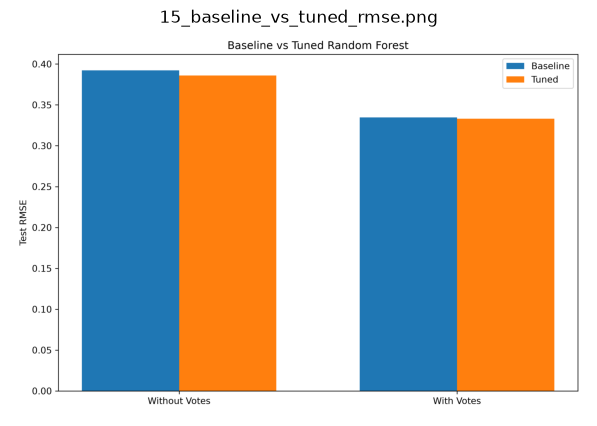

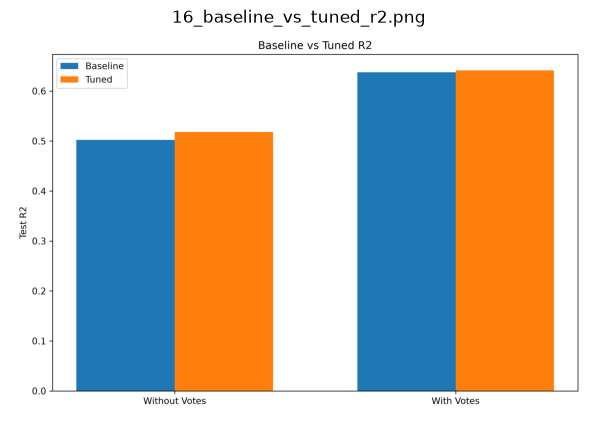

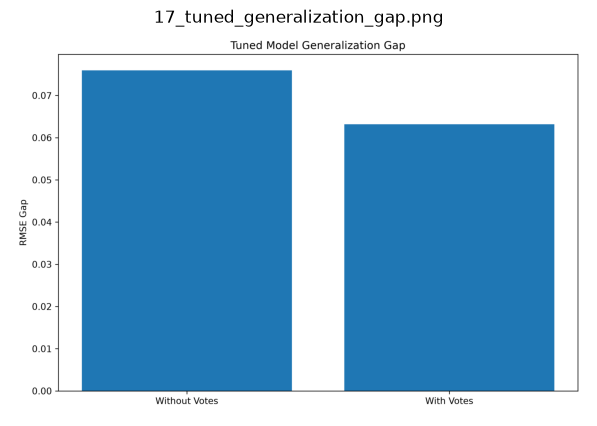

In [15]:
for name in ["15_baseline_vs_tuned_rmse.png",
             "16_baseline_vs_tuned_r2.png",
             "17_tuned_generalization_gap.png"]:
    path = FIGURES / name
    if path.exists():
        plt.figure(figsize=(9,5))
        plt.imshow(plt.imread(path))
        plt.axis("off")
        plt.title(name)
        plt.show()
    else:
        print("Figure not found:", name)

## 13. Review pipeline validation reports

In [16]:
summary_path = REPORTS / "rating_pipeline_validation_summary.csv"
pred_path = REPORTS / "rating_pipeline_test_predictions.csv"

if summary_path.exists():
    display(pd.read_csv(summary_path))
else:
    print("Pipeline validation summary not found.")

if pred_path.exists():
    display(pd.read_csv(pred_path).head(10))
else:
    print("Pipeline test predictions report not found.")

,Configuration,Input Records,Prediction Records,Single Prediction Test,Batch Prediction Test,Range Validation,MAE,MSE,RMSE,R2
0,without_votes,1481,1481,Passed,Passed,Passed,0.299258,0.148994,0.385998,0.518255
1,with_votes,1481,1481,Passed,Passed,Passed,0.246100,0.110898,0.333013,0.641432


,Configuration,Actual Rating,Predicted Rating,Absolute Error
0,without_votes,2.9,3.015560,0.115560
1,without_votes,3.9,3.519023,0.380977
2,without_votes,2.8,3.223159,0.423159
3,without_votes,2.3,3.239356,0.939356
4,without_votes,3.2,4.127056,0.927056
5,without_votes,3.0,3.353811,0.353811
6,without_votes,3.8,3.346926,0.453074
7,without_votes,3.3,3.427663,0.127663
8,without_votes,2.5,3.057976,0.557976
9,without_votes,3.4,3.554387,0.154387


## 14. Optional: interactive prediction history
This reads the history created by `src/task_1_rating_prediction/10_interactive_rating_prediction.py`; it does not launch the terminal application.

In [17]:
import csv

path = REPORTS / "interactive_rating_predictions.csv"

if path.exists():
    print("Inspecting:", path)

    with open(path, "r", encoding="utf-8-sig", newline="") as file:
        for line_number, line in enumerate(file, start=1):
            if line_number <= 6:
                print(f"Line {line_number}: {line.rstrip()}")

    print("\nChecking CSV structure...")

    try:
        with open(path, "r", encoding="utf-8-sig", newline="") as file:
            reader = csv.reader(file)
            for row_number, row in enumerate(reader, start=1):
                print(f"Row {row_number}: {len(row)} fields")

    except csv.Error as error:
        print("CSV structure error:", error)

else:
    print("No interactive prediction history file found yet.")


Inspecting: c:\Users\kamal\OneDrive\Desktop\DineScope\reports\task_1\interactive_rating_predictions.csv
Line 1: Restaurant Name,Model Configuration,Country Code,City,Cuisines,Has Table booking,Has Online delivery,Longitude,Latitude,Price range,Votes,Predicted Rating
Line 2: Demo Restaurant,without_votes,1,New Delhi,"North Indian, Chinese",No,Yes,77.2,28.6,2,,2.9060817700030546
Line 3: Demo Restaurant,with_votes,1,New Delhi,"North Indian, Chinese",No,Yes,77.2,28.6,2,150,3.272200983395338
Line 4: tgk,without_votes,1,abs,nothern indian,No,Yes,120.0,81.0,1,,3.400470190673095
Line 5: tgk,without_votes,1,tlr,mlr,No,Yes,120.0,81.0,1,,3.400470190673095
Line 6: tgk,with_votes,1,trl,mlr,No,Yes,120.0,81.0,1,5,2.8894500501857703

Checking CSV structure...
Row 1: 12 fields
Row 2: 12 fields
Row 3: 12 fields
Row 4: 12 fields
Row 5: 12 fields
Row 6: 12 fields
Row 7: 12 fields
Row 8: 12 fields
Row 9: 12 fields


## 15. Conclusion

Task 1's core regression workflow includes data auditing, exploratory analysis, preprocessing, model comparison, Random Forest tuning, final evaluation, pipeline testing and interactive inference.

### Key findings
- The rating task used 7,403 rated restaurants.
- Six regression estimators were compared in the initial experiment.
- Random Forest was selected for hyperparameter tuning.
- Separate tuned models were retained with and without Votes.
- The model with Votes achieved the stronger reported test performance.
- The terminal application provides a direct prediction interface.

### Limitations
1. Evaluation used a held-out split from the supplied dataset; independent external validation has not been established.
2. Votes may not be available for new restaurants and can reflect popularity.
3. Correlation and feature importance do not establish causation.
4. Ratings and restaurant characteristics can change over time.
5. The current prediction application is terminal-based, not a deployed web application.

**Primary model:** `models/task_1/tuned_rating_model_with_votes.joblib`  
**Fallback model:** `models/task_1/tuned_rating_model_without_votes.joblib`

**Task 1 status:** Core implementation and local pipeline verification completed. Further external validation and deployment hardening would be separate steps.

## 16. Interactive Restaurant Rating Prediction — Custom Input Testing

### Objective
Test the trained restaurant rating prediction models using custom restaurant details provided by the user.

### Instructions
1. Open the VS Code integrated terminal.
2. Ensure the DineScope virtual environment is activated.
3. Execute the interactive prediction application.
4. Enter the requested restaurant details.
5. Observe the predicted ratings from both models.
6. Verify that the predictions are displayed and saved successfully.

### Execute the application

Run the following command from the DineScope project root:

```powershell
python src/task_1_rating_prediction/10_interactive_rating_prediction.py
```

### Expected outcome
- Accept custom restaurant information.
- Validate the provided inputs.
- Generate predictions using the saved models.
- Compare predictions with and without Votes.
- Display the predicted restaurant rating.
- Save the prediction history.

**Note:** This application uses the trained models generated during the Task 1 implementation. It does not retrain the models.